# F20a: Approksimasjon av deriverte -- fremover-, bakover- og sentraldifferanse

I denne notatboken ser vi på de enkleste byggeklossene for endelige differansemetoder: approksimasjoner til $f'(x)$ og $f''(x)$ basert kun på funksjonsevalueringer, fra kompendiets §3.3 "Approksimasjon av deriverte".

Vi implementerer og sammenligner
$$
f'(x) \approx
\begin{cases}
\dfrac{f(x+h)-f(x)}{h}, & \text{fremoverdifferanse}, \\[4pt]
\dfrac{f(x)-f(x-h)}{h}, & \text{bakoverdifferanse}, \\[4pt]
\dfrac{f(x+h)-f(x-h)}{2h}, & \text{sentraldifferanse},
\end{cases}
$$
samt differanseformelen for andrederiverte,
$$
f''(x) \approx \frac{f(x+h)-2f(x)+f(x-h)}{h^2}.
$$

Dette er nøyaktig de samme byggeklossene som brukes til å diskretisere randverdiproblemene i **F20b**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. De tre differanseformlene for $f'(x)$

Vi implementerer hver formel som en egen funksjon av `f`, `x` og steglengden `h`.

In [2]:
def fremoverdiff(f, x, h):
    '''Fremoverdifferanse: approksimasjon til f'(x).'''
    return (f(x + h) - f(x)) / h

def bakoverdiff(f, x, h):
    '''Bakoverdifferanse: approksimasjon til f'(x).'''
    return (f(x) - f(x - h)) / h

def sentraldiff(f, x, h):
    '''Sentraldifferanse: approksimasjon til f'(x) (gjennomsnittet av fremover- og bakoverdifferansen).'''
    return (f(x + h) - f(x - h)) / (2 * h)

def andrederivertdiff(f, x, h):
    '''Differanseformel for andrederiverte f''(x), basert på punktene x-h, x, x+h.'''
    return (f(x + h) - 2 * f(x) + f(x - h)) / h**2

### Test: $f(x) = \sin x$ i $x_0=1$

Vi tester formlene på $f(x)=\sin x$, der vi kjenner de eksakte deriverte $f'(x)=\cos x$ og $f''(x)=-\sin x$.

In [3]:
f = np.sin
x0 = 1.0
h = 0.1

fp_eksakt = np.cos(x0) #førstederivert av sin(x) er cos(x)
fpp_eksakt = -np.sin(x0) #andrerderivert av sin(x) er -sin(x)

print(f"Eksakt f'({x0})  = {fp_eksakt:.6f}")
print(f"Fremoverdifferanse: {fremoverdiff(f, x0, h): .6f}   (feil: {abs(fremoverdiff(f, x0, h) - fp_eksakt):.2e})")
print(f"Bakoverdifferanse:  {bakoverdiff(f, x0, h): .6f}   (feil: {abs(bakoverdiff(f, x0, h) - fp_eksakt):.2e})")
print(f"Sentraldifferanse:  {sentraldiff(f, x0, h): .6f}   (feil: {abs(sentraldiff(f, x0, h) - fp_eksakt):.2e})")
print()
print(f"Eksakt f''({x0}) = {fpp_eksakt:.6f}")
print(f"Andrederivert-differanse: {andrederivertdiff(f, x0, h): .6f}   (feil: {abs(andrederivertdiff(f, x0, h) - fpp_eksakt):.2e})")

Eksakt f'(1.0)  = 0.540302
Fremoverdifferanse:  0.497364   (feil: 4.29e-02)
Bakoverdifferanse:   0.581441   (feil: 4.11e-02)
Sentraldifferanse:   0.539402   (feil: 9.00e-04)

Eksakt f''(1.0) = -0.841471
Andrederivert-differanse: -0.840770   (feil: 7.01e-04)


### Nøyaktighet, fordeler og ulemper

Allerede i tallene over ser vi et mønster: med $h=0.1$ bommer fremover- og bakoverdifferansen med omtrent $4\cdot10^{-2}$, mens sentraldifferansen bommer med omtrent $9\cdot10^{-4}$ -- rundt 50 ganger mindre. Dette er ikke tilfeldig, og det er grunnen til at man som regel foretrekker sentraldifferansen når man kan velge fritt:

| Metode | Krever | Nøyaktighet | Når brukes den |
|---|---|---|---|
| Fremoverdifferanse | $f(x)$, $f(x+h)$ | $O(h)$ (lav) | I venstre endepunkt av et intervall, der $f(x-h)$ ikke finnes/ikke er kjent |
| Bakoverdifferanse | $f(x)$, $f(x-h)$ | $O(h)$ (lav) | I høyre endepunkt av et intervall, der $f(x+h)$ ikke finnes/ikke er kjent |
| Sentraldifferanse | $f(x-h)$, $f(x+h)$ | $O(h^2)$ (høy) | I alle indre punkter, der begge naboverdiene er tilgjengelige |

Kort fortalt: fremover- og bakoverdifferansen er **ensidige** -- de bruker bare informasjon på én side av $x$, noe som gjør dem uunnværlige ved randen av et intervall, men de betaler for dette med at feilen bare avtar proporsjonalt med $h$ ($O(h)$). Sentraldifferansen er **tosidig** og bruker informasjon symmetrisk rundt $x$; de asymmetriske leddene i feilen kansellerer da hverandre, slik at feilen avtar proporsjonalt med $h^2$ ($O(h^2)$) -- halverer du $h$, blir feilen omtrent fire ganger mindre, ikke bare to.

Vi bekrefter dette numerisk i del 3 under, og bruker det samme prinsippet i **F20b** og **F20c**: der brukes sentraldifferansen i de indre punktene av randverdiproblemet, mens Dirichlet-betingelsene (F20b) og Neumann-betingelsene (F20c) håndterer endepunktene på andre måter.

## 2. Geometrisk tolkning: sekantlinjer mot tangenten

Fremover-, bakover- og sentraldifferansen er stigningstall til hver sin sekantlinje gjennom punkter på grafen til $f$. Vi plotter dem sammen med den eksakte tangentlinjen i $x=x_0$, for en stor nok $h$ til at forskjellene er godt synlige.

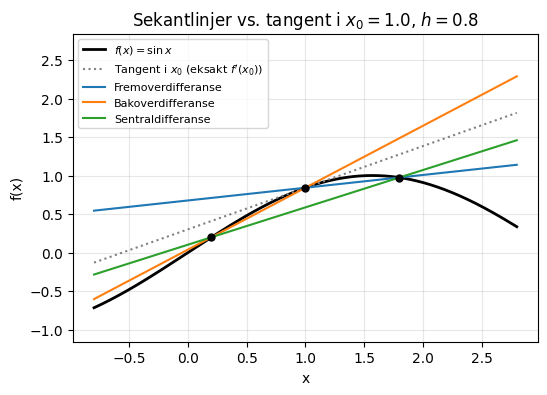

In [4]:
h_vis = 0.8  # stor h, kun for å gjøre figuren tydelig

x_plot = np.linspace(x0 - 1.8, x0 + 1.8, 400)

def tangentlinje(x):
    return f(x0) + np.cos(x0) * (x - x0)

def sekant(xa, xb):
    stigning = (f(xb) - f(xa)) / (xb - xa)
    return lambda x: f(xa) + stigning * (x - xa)

sek_frem = sekant(x0, x0 + h_vis)
sek_bak = sekant(x0 - h_vis, x0)
sek_sentral = sekant(x0 - h_vis, x0 + h_vis)

plt.figure(figsize=(6, 4))
plt.plot(x_plot, f(x_plot), 'k-', lw=2, label=r"$f(x)=\sin x$")
plt.plot(x_plot, tangentlinje(x_plot), color='gray', ls=':', label="Tangent i $x_0$ (eksakt $f'(x_0)$)")
plt.plot(x_plot, sek_frem(x_plot), label="Fremoverdifferanse")
plt.plot(x_plot, sek_bak(x_plot), label="Bakoverdifferanse")
plt.plot(x_plot, sek_sentral(x_plot), label="Sentraldifferanse")
plt.plot([x0 - h_vis, x0, x0 + h_vis], [f(x0 - h_vis), f(x0), f(x0 + h_vis)], 'ko', ms=5)
plt.ylim(f(x0) - 2, f(x0) + 2)
plt.xlabel("x"); plt.ylabel("f(x)")
plt.title(f"Sekantlinjer vs. tangent i $x_0={x0}$, $h={h_vis}$")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.show()

Legg merke til at sentraldifferansens sekant (gjennom $x_0-h$ og $x_0+h$) ligger tettest opptil tangentlinjen av de tre -- en visuell bekreftelse på at den er mest nøyaktig, selv med en $h$ så stor at forskjellene er lette å se med øyet.

## 3. Hvor fort avtar feilen når $h\to 0$?

Vi bekrefter nå påstanden fra del 1 numerisk: vi regner ut feilen for en rekke avtagende $h$-verdier og plotter feil mot $h$ i et log-log-plott, sammen med referanselinjene $O(h)$ og $O(h^2)$.

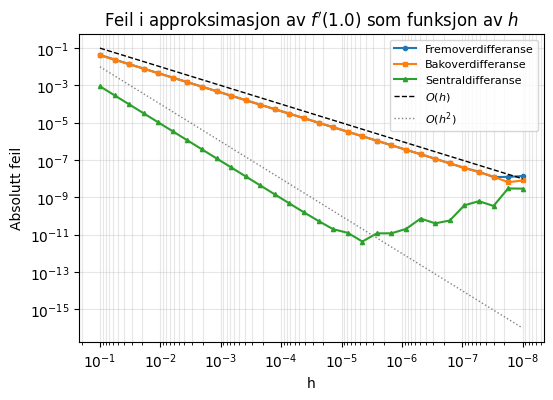

In [5]:
h_verdier = np.logspace(-1, -8, 30)

feil_frem = np.array([abs(fremoverdiff(f, x0, h) - fp_eksakt) for h in h_verdier])
feil_bak = np.array([abs(bakoverdiff(f, x0, h) - fp_eksakt) for h in h_verdier])
feil_sentral = np.array([abs(sentraldiff(f, x0, h) - fp_eksakt) for h in h_verdier])

plt.figure(figsize=(6, 4))
plt.loglog(h_verdier, feil_frem, 'o-', ms=3, label="Fremoverdifferanse")
plt.loglog(h_verdier, feil_bak, 's-', ms=3, label="Bakoverdifferanse")
plt.loglog(h_verdier, feil_sentral, '^-', ms=3, label="Sentraldifferanse")
plt.loglog(h_verdier, h_verdier, 'k--', lw=1, label=r"$O(h)$")
plt.loglog(h_verdier, h_verdier**2, color='gray', ls=':', lw=1, label=r"$O(h^2)$")
plt.xlabel("h"); plt.ylabel("Absolutt feil")
plt.title(f"Feil i approksimasjon av $f'({x0})$ som funksjon av $h$")
plt.legend(fontsize=8); plt.grid(alpha=0.3, which='both')
plt.gca().invert_xaxis()
plt.show()

Som ventet følger fremover- og bakoverdifferansen $O(h)$-linjen -- feilen halveres omtrent når $h$ halveres -- mens sentraldifferansen følger $O(h^2)$-linjen -- feilen firedobles når $h$ dobles. For en gitt $h$ er sentraldifferansen altså systematisk mer nøyaktig, akkurat som sekant-plottet over antydet.

Helt til høyre i plottet (svært små $h$) flater feilen ut og øker igjen for alle tre metodene. Det skyldes avrundingsfeil i flyttallsregningen -- $f(x+h)-f(x)$ blir en differanse mellom to nesten like store tall, og man mister sifre -- og ikke noe galt med formlene selv. I praksis betyr det at man ikke kan gjøre $h$ vilkårlig liten for å få vilkårlig god nøyaktighet; det finnes en optimal $h$. Dette er utenfor pensum i dette kurset, men greit å være klar over.

## 4. Andrederivert-differansen

Vi gjør tilsvarende sjekk for differanseformelen for $f''(x)$, som (som sentraldifferansen) er tosidig og $O(h^2)$.

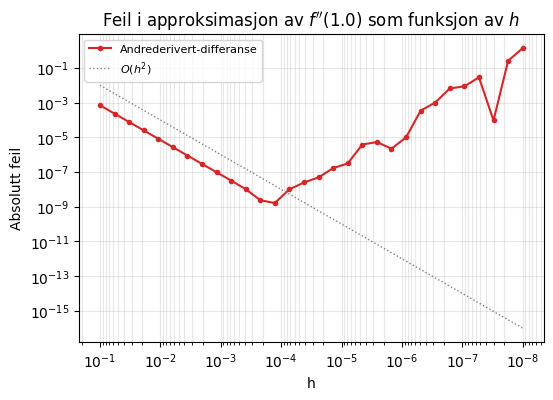

In [6]:
feil_andre = np.array([abs(andrederivertdiff(f, x0, h) - fpp_eksakt) for h in h_verdier])

plt.figure(figsize=(6, 4))
plt.loglog(h_verdier, feil_andre, 'o-', ms=3, color='C3', label="Andrederivert-differanse")
plt.loglog(h_verdier, h_verdier**2, color='gray', ls=':', lw=1, label=r"$O(h^2)$")
plt.xlabel("h"); plt.ylabel("Absolutt feil")
plt.title(f"Feil i approksimasjon av $f''({x0})$ som funksjon av $h$")
plt.legend(fontsize=8); plt.grid(alpha=0.3, which='both')
plt.gca().invert_xaxis()
plt.show()

## Oppsummering

- **Fremover-** og **bakoverdifferansen** er ensidige og krever bare én ekstra funksjonsevaluering ($f(x+h)$ eller $f(x-h)$), men feilen er $O(h)$. De er nødvendige ved endepunktene av et intervall, der man ikke har en funksjonsverdi på begge sider.
- **Sentraldifferansen** er tosidig og krever funksjonsverdier på begge sider av $x$, men gir $O(h^2)$-nøyaktighet -- den foretrekkes derfor nesten alltid i indre punkter, der den er tilgjengelig.
- Differanseformelen for $f''(x)$ bruker de samme tre punktene $x-h,\,x,\,x+h$ som sentraldifferansen for $f'(x)$, er også $O(h^2)$, og er det vi bruker videre i **F20b** til å diskretisere $u''$ i randverdiproblemer.